# 08: Results tables with paired-bootstrap intervals

This notebook puts every condition on the same footing: a mean and a 95% interval for each metric, core and subfield questions **separately** (as the ScholarCatalyst paper reports them), and a paired test for each one-change comparison. It also runs the two extra checks of the plan: memorization of training positives, and source papers before vs after the Qwen3 release.

**Why a bootstrap over projects.** The 894 questions come from 207 projects. Questions of one project share a source paper and often credited papers, so their scores rise and fall together; 207, not 894, is the real number of independent units. A bootstrap sample draws 207 projects *with replacement* and keeps all questions of each drawn project (`insight.stats`, tests in `tests/test_stats.py`).

**Notation.** For a metric (say Recall@20) let $x_i^{(A)}$ and $x_i^{(B)}$ be the scores of conditions $A$ and $B$ on question $i$, and $d_i = x_i^{(B)} - x_i^{(A)}$. The reported difference is $\bar d$, the mean of $d_i$ over questions. Each bootstrap sample $b$ gives a resampled mean $\bar d^{*}_b$; the 95% interval is the 2.5th to 97.5th percentile of the $\bar d^{*}_b$ over $10{,}000$ samples, and the two-sided $p$ value is $2\min\big(P^*(\bar d^* \le 0),\, P^*(\bar d^* \ge 0)\big)$. *Paired* means both conditions are scored on the same resampled questions, so per-question difficulty cancels.

**Inputs** (all in `results/`): per-question metric files `metrics_{A,B,B06,C,D,E,D_core,rq3}.csv`, ranked runs and shortlists, pair scores `pairs_{C,D,E,D_core}.parquet`, and `folds.csv`. Settings: `configs/stats.yaml`.

**Not here yet:** the RQ3 full pipeline (the RQ3 shortlist rescored by E's adapters, GPU queue item 9). The tables pick it up automatically if `metrics_E_rq3.csv` exists.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from insight import data, stats, metrics
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
R = data.ROOT / "results"
ds = data.load()
table = ds.table
cfg = stats.StatsConfig.from_yaml(data.ROOT / "configs" / "stats.yaml")
kw = dict(n_boot=cfg.n_boot, seed=cfg.seed, ci=cfg.ci)
print(cfg)

files = {"A": "A", "B": "B", "B06": "B06", "C": "C", "D": "D", "E": "E", "D_core": "D_core",
         "RQ3": "rq3", "E_rq3": "E_rq3"}
per_q = {k: pd.read_csv(R / f"metrics_{v}.csv", index_col="query_id")
         for k, v in files.items() if (R / f"metrics_{v}.csv").exists()}
project_of = table.paper_id
for k, v in per_q.items():
    assert set(v.index) == set(table.index), k
    assert (v.kind == table.kind.loc[v.index]).all(), k
    print(f"{k:7s} {len(v)} questions, pairwise accuracy: {'pairwise_acc' in v}")
print("projects:", project_of.nunique())

StatsConfig(n_boot=10000, seed=0, ci=0.95, release_date='2025-06-05', seen_roles=('train', 'val'))
A       894 questions, pairwise accuracy: False
B       894 questions, pairwise accuracy: False
B06     894 questions, pairwise accuracy: False
C       894 questions, pairwise accuracy: True
D       894 questions, pairwise accuracy: True
E       894 questions, pairwise accuracy: True
D_core  894 questions, pairwise accuracy: True
RQ3     894 questions, pairwise accuracy: False
projects: 207


## 1. Every condition, with intervals

Columns are mean [lower, upper] of the 95% project-bootstrap interval. Reminders: **A** BM25; **B** frozen Qwen3-Embedding-4B (its top 100 is the shortlist C, D, E rescore); **B06** frozen Qwen3-Embedding-0.6B; **C** off-the-shelf Qwen3-Reranker-0.6B with the inspiration instruction; **D** C plus LoRA trained on credited vs author-rejected pairs; **E** D plus mined negatives from shortlist ranks 30 to 100; **D_core** D trained on core questions only; **RQ3** fine-tuned Qwen3-Embedding-0.6B (one model per fold). Pairwise accuracy needs a score for every labeled paper, which only the rerankers have; 37 subfield questions have no rejected paper, so subfield pairwise accuracy covers 650 questions.

In [2]:
M = ["recall@5", "recall@20", "recall@100", "ndcg@20", "pairwise_acc"]
summary = stats.summarize(per_q, M, project_of, **kw)
summary.to_csv(R / "stats_summary.csv", index=False)
fmt = summary.assign(cell=summary.apply(lambda r: f"{r['mean']:.4f} [{r.lo:.4f}, {r.hi:.4f}]", axis=1))
for kind in ["core", "subfield"]:
    t = fmt[fmt.kind == kind].pivot(index="condition", columns="metric", values="cell")
    t = t.reindex(index=[k for k in per_q], columns=M).fillna("")
    print(f"\n{kind} questions")
    display(t)


core questions


metric,recall@5,recall@20,recall@100,ndcg@20,pairwise_acc
condition,,,,,
A,"0.1225 [0.0944, 0.1526]","0.2406 [0.2028, 0.2809]","0.4171 [0.3714, 0.4630]","0.1644 [0.1371, 0.1928]",
B,"0.1846 [0.1527, 0.2187]","0.3785 [0.3337, 0.4253]","0.5971 [0.5500, 0.6438]","0.2539 [0.2214, 0.2878]",
B06,"0.1887 [0.1545, 0.2252]","0.3270 [0.2837, 0.3715]","0.5288 [0.4812, 0.5770]","0.2345 [0.2016, 0.2692]",
C,"0.1836 [0.1490, 0.2189]","0.3432 [0.2978, 0.3897]","0.5971 [0.5500, 0.6438]","0.2296 [0.1972, 0.2627]","0.4948 [0.4575, 0.5330]"
D,"0.0962 [0.0709, 0.1232]","0.2346 [0.1976, 0.2720]","0.5971 [0.5500, 0.6438]","0.1408 [0.1169, 0.1660]","0.6471 [0.6166, 0.6768]"
E,"0.1492 [0.1177, 0.1832]","0.3061 [0.2648, 0.3477]","0.5971 [0.5500, 0.6438]","0.1947 [0.1658, 0.2239]","0.6418 [0.6100, 0.6735]"
D_core,"0.0912 [0.0647, 0.1198]","0.2051 [0.1696, 0.2431]","0.5971 [0.5500, 0.6438]","0.1261 [0.1011, 0.1532]","0.6466 [0.6152, 0.6775]"
RQ3,"0.1775 [0.1439, 0.2134]","0.3400 [0.2946, 0.3866]","0.5420 [0.4928, 0.5900]","0.2351 [0.2008, 0.2709]",



subfield questions


metric,recall@5,recall@20,recall@100,ndcg@20,pairwise_acc
condition,,,,,
A,"0.1270 [0.1130, 0.1415]","0.2853 [0.2643, 0.3068]","0.4876 [0.4605, 0.5141]","0.2275 [0.2098, 0.2456]",
B,"0.2233 [0.2045, 0.2430]","0.4489 [0.4239, 0.4748]","0.6967 [0.6705, 0.7232]","0.3663 [0.3432, 0.3898]",
B06,"0.1733 [0.1566, 0.1903]","0.3667 [0.3416, 0.3923]","0.5971 [0.5698, 0.6245]","0.2957 [0.2737, 0.3182]",
C,"0.1803 [0.1638, 0.1968]","0.4042 [0.3792, 0.4293]","0.6967 [0.6705, 0.7232]","0.3078 [0.2871, 0.3287]","0.5643 [0.5423, 0.5868]"
D,"0.1122 [0.0991, 0.1256]","0.2771 [0.2588, 0.2957]","0.6967 [0.6705, 0.7232]","0.2027 [0.1884, 0.2173]","0.6331 [0.6165, 0.6495]"
E,"0.1764 [0.1588, 0.1946]","0.3773 [0.3539, 0.4007]","0.6967 [0.6705, 0.7232]","0.2897 [0.2704, 0.3090]","0.6467 [0.6301, 0.6634]"
D_core,"0.0744 [0.0633, 0.0862]","0.2249 [0.2072, 0.2430]","0.6967 [0.6705, 0.7232]","0.1508 [0.1386, 0.1635]","0.5855 [0.5687, 0.6022]"
RQ3,"0.1962 [0.1771, 0.2157]","0.3913 [0.3661, 0.4170]","0.6245 [0.5983, 0.6504]","0.3186 [0.2960, 0.3416]",


## 2. One-change comparisons

Each row changes one thing (Section 5 of the plan): A to B (keywords to meaning), B to C (an untrained second look), **C to D (learning from authors, the key result)**, D to E (adding mined negatives), D_core to D (adding subfield questions to training), and B to E (does the best trained reranker beat the order it rescores). For RQ3: B06 to RQ3 isolates training, B to RQ3 is the pipeline comparison. Recall@100 is shown only for the retriever comparisons, since a reranker cannot change what is in the top 100.

In [3]:
rerank_pairs = [("A", "B"), ("B", "C"), ("C", "D"), ("D", "E"), ("D_core", "D"), ("B", "E")]
retr_pairs = [("B06", "RQ3"), ("B", "RQ3")]
if "E_rq3" in per_q:
    retr_pairs += [("RQ3", "E_rq3"), ("B", "E_rq3")]
parts = []
for m in ["recall@20", "ndcg@20"]:
    parts.append(stats.compare(per_q, rerank_pairs + retr_pairs, m, project_of, **kw))
parts.append(stats.compare(per_q, retr_pairs[:2] + [("A", "B")], "recall@100", project_of, **kw))
pa_pairs = [p for p in [("C", "D"), ("D", "E"), ("D_core", "D"), ("C", "E")]
            if "pairwise_acc" in per_q[p[0]] and "pairwise_acc" in per_q[p[1]]]
parts.append(stats.compare(per_q, pa_pairs, "pairwise_acc", project_of, **kw))
comp = pd.concat(parts, ignore_index=True)
comp.to_csv(R / "stats_comparisons.csv", index=False)
show = comp.assign(comparison=comp.a + " to " + comp.b)[
    ["comparison", "kind", "metric", "mean_a", "mean_b", "diff", "lo", "hi", "p", "n_questions", "n_projects"]]
display(show)

,comparison,kind,metric,mean_a,mean_b,diff,lo,hi,p,n_questions,n_projects
0,A to B,core,recall@20,0.2406,0.3785,0.1379,0.0966,0.1809,0.0000,207,207
1,A to B,subfield,recall@20,0.2853,0.4489,0.1636,0.1418,0.1860,0.0000,687,207
2,B to C,core,recall@20,0.3785,0.3432,-0.0353,-0.0738,0.0022,0.0688,207,207
3,B to C,subfield,recall@20,0.4489,0.4042,-0.0447,-0.0632,-0.0269,0.0000,687,207
4,C to D,core,recall@20,0.3432,0.2346,-0.1086,-0.1563,-0.0624,0.0000,207,207
5,C to D,subfield,recall@20,0.4042,0.2771,-0.1271,-0.1517,-0.1035,0.0000,687,207
6,D to E,core,recall@20,0.2346,0.3061,0.0716,0.0301,0.1132,0.0006,207,207
7,D to E,subfield,recall@20,0.2771,0.3773,0.1002,0.0826,0.1187,0.0000,687,207
8,D_core to D,core,recall@20,0.2051,0.2346,0.0294,-0.0089,0.0672,0.1328,207,207
9,D_core to D,subfield,recall@20,0.2249,0.2771,0.0522,0.0322,0.0717,0.0000,687,207


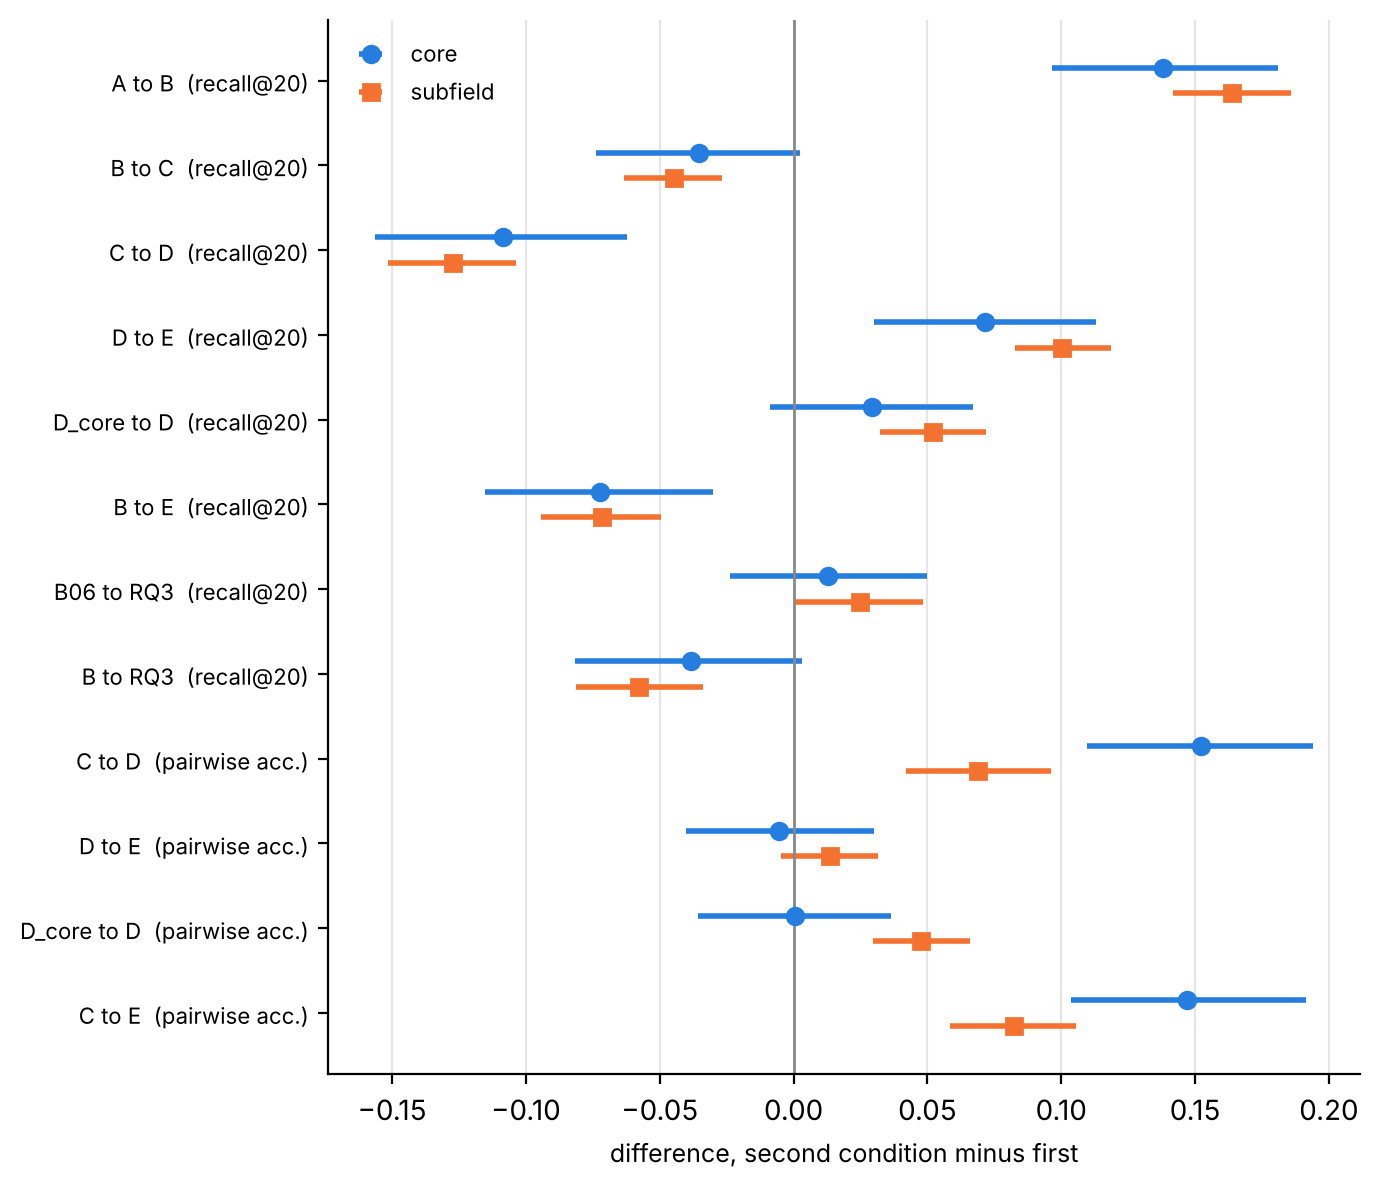

In [4]:
sel = comp[comp.metric.isin(["recall@20", "pairwise_acc"])].copy()
sel["label"] = sel.a + " to " + sel.b + "  (" + sel.metric.str.replace("pairwise_acc", "pairwise acc.") + ")"
labels = list(dict.fromkeys(sel.label))
fig, ax = plt.subplots(figsize=(7, 0.42 * len(labels) + 1))
colors = {"core": "#257de0", "subfield": "#f47230"}
markers = {"core": "o", "subfield": "s"}
for j, kind in enumerate(["core", "subfield"]):
    g = sel[sel.kind == kind].set_index("label").reindex(labels)
    y = np.arange(len(labels)) + (j - 0.5) * 0.3
    ax.errorbar(g["diff"], y, xerr=[g["diff"] - g.lo, g.hi - g["diff"]], fmt=markers[kind], ms=6,
                color=colors[kind], elinewidth=2, capsize=0, label=kind)
ax.axvline(0, color="#888888", lw=1)
ax.set_yticks(np.arange(len(labels)), labels, fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("difference, second condition minus first", fontsize=9)
ax.grid(axis="x", color="#e5e5e5", lw=0.8)
ax.set_axisbelow(True)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
ax.legend(fontsize=8, frameon=False, loc="upper left")
fig.tight_layout()
(R / "figures").mkdir(exist_ok=True)
fig.savefig(R / "figures" / "paired_differences.png", dpi=200)
plt.show()

<small>**Figure.** Each row is a one-change comparison "X to Y"; the dot is the mean per-question difference $\bar d$ (Y minus X) and the bar its 95% paired-bootstrap interval over 207 projects (10,000 samples). Blue circles: core questions (207); orange squares: subfield questions (687, or 650 for pairwise accuracy). Grey line: no difference. Saved to `results/figures/paired_differences.png`.</small>

In [5]:
def line(a, b, kind, m):
    r = comp[(comp.a == a) & (comp.b == b) & (comp.kind == kind) & (comp.metric == m)].iloc[0]
    return f"{a} to {b}, {kind} {m}: {r['diff']:+.4f} [{r.lo:+.4f}, {r.hi:+.4f}], p = {r.p:.4f}"
for kind in ["core", "subfield"]:
    for a, b, m in [("C", "D", "pairwise_acc"), ("C", "D", "recall@20"), ("B", "C", "recall@20"),
                    ("D", "E", "recall@20"), ("B", "E", "recall@20"), ("D_core", "D", "pairwise_acc"),
                    ("B06", "RQ3", "recall@100"), ("B", "RQ3", "recall@100")]:
        print(line(a, b, kind, m))
    print()

C to D, core pairwise_acc: +0.1523 [+0.1096, +0.1941], p = 0.0000
C to D, core recall@20: -0.1086 [-0.1563, -0.0624], p = 0.0000
B to C, core recall@20: -0.0353 [-0.0738, +0.0022], p = 0.0688
D to E, core recall@20: +0.0716 [+0.0301, +0.1132], p = 0.0006
B to E, core recall@20: -0.0724 [-0.1153, -0.0303], p = 0.0012
D_core to D, core pairwise_acc: +0.0005 [-0.0357, +0.0364], p = 0.9948
B06 to RQ3, core recall@100: +0.0132 [-0.0252, +0.0499], p = 0.5024
B to RQ3, core recall@100: -0.0550 [-0.0960, -0.0136], p = 0.0062

C to D, subfield pairwise_acc: +0.0688 [+0.0419, +0.0962], p = 0.0000
C to D, subfield recall@20: -0.1271 [-0.1517, -0.1035], p = 0.0000
B to C, subfield recall@20: -0.0447 [-0.0632, -0.0269], p = 0.0000
D to E, subfield recall@20: +0.1002 [+0.0826, +0.1187], p = 0.0000
B to E, subfield recall@20: -0.0716 [-0.0942, -0.0494], p = 0.0000
D_core to D, subfield pairwise_acc: +0.0477 [+0.0297, +0.0659], p = 0.0000
B06 to RQ3, subfield recall@100: +0.0275 [+0.0044, +0.0509], p 

## 3. Memorization check

The same paper can be credited for a training question and a test question (decision log, Oct 28: not leakage, but measured). A trained model could then rank it high because it was a training positive, not because it learned what makes a paper inspiring. So each held-out credited (question, paper) pair is flagged **seen** when that paper is credited for a training or validation question of the same fold (`stats.seen_positive_flags`, roles from `configs/stats.yaml`), and the metrics are computed separately over seen and unseen credited papers.

- **Recall@20 by group**: for question $i$, the share of its seen (or unseen) credited papers in the top 20; a question enters a group only if it has at least one credited paper of that kind.
- **Pairwise accuracy by group**: the credited side of the pairs is restricted to seen (or unseen) papers; the rejected side is unchanged.

C was never trained, so for C "seen" only marks which papers are popular across projects; the question is whether training changes the gap.

In [6]:
folds = pd.read_csv(R / "folds.csv")
flags = stats.seen_positive_flags(table, folds, cfg.seen_roles)
flags["kind"] = table.kind.loc[flags.query_id].to_numpy()
print("held-out credited pairs:", len(flags))
display(flags.groupby("kind").seen.agg(n_seen="sum", n_pairs="size", share="mean"))
display(flags.groupby("fold").seen.agg(n_seen="sum", n_pairs="size", share="mean"))

held-out credited pairs: 4845


,n_seen,n_pairs,share
kind,,,
core,83,661,0.1256
subfield,519,4184,0.1240


,n_seen,n_pairs,share
fold,,,
0,103,995,0.1035
1,133,1006,0.1322
2,127,1011,0.1256
3,123,972,0.1265
4,116,861,0.1347


In [7]:
run_files = {"B": "shortlist_B", "B06": "shortlist_B06", "C": "run_C", "D": "run_D", "E": "run_E",
             "D_core": "run_D_core", "RQ3": "shortlist_rq3", "E_rq3": "run_E_rq3"}
runs = {k: pd.read_parquet(R / f"{v}.parquet") for k, v in run_files.items() if (R / f"{v}.parquet").exists()}
by_seen = {k: stats.recall_by_flag(flags, run, "seen", k=20) for k, run in runs.items()}
rows = []
for k, t in by_seen.items():
    for kind in ["core", "subfield"]:
        for fl in [True, False]:
            col = t[fl][(table.kind.loc[t.index] == kind).to_numpy()].dropna()
            r = stats.bootstrap_ci(col, project_of.loc[col.index], **kw)
            rows.append({"condition": k, "kind": kind, "group": "seen" if fl else "unseen", **r})
mem_recall = pd.DataFrame(rows)
display(mem_recall.pivot_table(index="condition", columns=["kind", "group"], values="mean", sort=False))
display(mem_recall)

kind         core         subfield        
group        seen  unseen     seen  unseen
condition                                 
B          0.2141  0.3925   0.3402  0.4490
B06        0.1859  0.3393   0.2816  0.3690
C          0.2423  0.3476   0.3146  0.4083
D          0.2051  0.2418   0.3014  0.2666
E          0.3167  0.3018   0.4244  0.3618
D_core     0.1936  0.2020   0.2252  0.2217
RQ3        0.2692  0.3506   0.4239  0.3742

,condition,kind,group,mean,lo,hi,n_questions,n_projects
0,B,core,seen,0.2141,0.1244,0.3115,65,65
1,B,core,unseen,0.3925,0.3434,0.4403,201,201
2,B,subfield,seen,0.3402,0.2907,0.3907,259,148
3,B,subfield,unseen,0.4490,0.4232,0.4755,674,207
4,B06,core,seen,0.1859,0.1013,0.2808,65,65
5,B06,core,unseen,0.3393,0.2923,0.3863,201,201
6,B06,subfield,seen,0.2816,0.2369,0.3280,259,148
7,B06,subfield,unseen,0.3690,0.3432,0.3956,674,207
8,C,core,seen,0.2423,0.1513,0.3423,65,65
9,C,core,unseen,0.3476,0.2997,0.3958,201,201


In [8]:
seen_set = set(zip(flags.query_id[flags.seen], flags.doc_id[flags.seen]))
def pacc_by_seen(pairs):
    out = {}
    for q, g in pairs.groupby("query_id"):
        s = dict(zip(g.doc_id, g.score))
        pos, neg = g.doc_id[g.label == 1], g.doc_id[g.label == 0]
        out[q] = {grp: metrics.pairwise_accuracy(s, [d for d in pos if ((q, d) in seen_set) == fl], neg)
                  for grp, fl in [("seen", True), ("unseen", False)]}
    return pd.DataFrame(out).T
pacc = {c: pacc_by_seen(pd.read_parquet(R / f"pairs_{c}.parquet")) for c in ["C", "D", "E", "D_core"]}
rows = []
for c, t in pacc.items():
    for kind in ["core", "subfield"]:
        for grp in ["seen", "unseen"]:
            col = t[grp][(table.kind.loc[t.index] == kind).to_numpy()].dropna()
            rows.append({"condition": c, "kind": kind, "group": grp,
                         **stats.bootstrap_ci(col, project_of.loc[col.index], **kw)})
mem_pacc = pd.DataFrame(rows)
display(mem_pacc.pivot_table(index="condition", columns=["kind", "group"], values="mean", sort=False))

kind         core         subfield        
group        seen  unseen     seen  unseen
condition                                 
C          0.4163  0.5040   0.5405  0.5672
D          0.7433  0.6320   0.7380  0.6160
E          0.7645  0.6191   0.7464  0.6273
D_core     0.7298  0.6290   0.6427  0.5777

The honest estimate of what training learned is the gain on **unseen** credited papers, since memorizing them was impossible. Paired comparisons within each group (RQ3 also on Recall@100, its main metric):

In [9]:
by_seen100 = {k: stats.recall_by_flag(flags, runs[k], "seen", k=100) for k in ["B06", "RQ3"]}
rows = []
def paired_group(A, B, grp, kind, a, b, metric):
    q = A.index.intersection(B.index)
    q = q[(table.kind.loc[q] == kind).to_numpy()]
    r = stats.paired_bootstrap(A.loc[q, grp], B.loc[q, grp], project_of.loc[q], **kw)
    rows.append({"comparison": f"{a} to {b}", "metric": metric, "kind": kind, "group": grp, **r})
for kind in ["core", "subfield"]:
    for grp in ["seen", "unseen"]:
        for a, b in [("C", "D"), ("C", "E")]:
            paired_group(pacc[a], pacc[b], grp, kind, a, b, "pairwise_acc")
    for fl, grp in [(True, "seen"), (False, "unseen")]:
        for a, b in [("C", "D"), ("C", "E"), ("B06", "RQ3")]:
            A = by_seen[a].rename(columns={True: "seen", False: "unseen"})
            B = by_seen[b].rename(columns={True: "seen", False: "unseen"})
            paired_group(A, B, grp, kind, a, b, "recall@20")
        A = by_seen100["B06"].rename(columns={True: "seen", False: "unseen"})
        B = by_seen100["RQ3"].rename(columns={True: "seen", False: "unseen"})
        paired_group(A, B, grp, kind, "B06", "RQ3", "recall@100")
mem_comp = pd.DataFrame(rows)
mem = pd.concat([mem_recall.assign(metric="recall@20"), mem_pacc.assign(metric="pairwise_acc")])
mem.to_csv(R / "stats_memorization.csv", index=False)
mem_comp.to_csv(R / "stats_memorization_comparisons.csv", index=False)
display(mem_comp)

,comparison,metric,kind,group,mean_a,mean_b,diff,lo,hi,p,n_questions,n_projects
0,C to D,pairwise_acc,core,seen,0.4163,0.7433,0.3270,0.2133,0.4361,0.0000,65,65
1,C to E,pairwise_acc,core,seen,0.4163,0.7645,0.3482,0.2427,0.4521,0.0000,65,65
2,C to D,pairwise_acc,core,unseen,0.5040,0.6320,0.1279,0.0847,0.1706,0.0000,201,201
3,C to E,pairwise_acc,core,unseen,0.5040,0.6191,0.1150,0.0729,0.1579,0.0000,201,201
4,C to D,recall@20,core,seen,0.2423,0.2051,-0.0372,-0.1564,0.0821,0.5484,65,65
5,C to E,recall@20,core,seen,0.2423,0.3167,0.0744,-0.0154,0.1744,0.1116,65,65
6,B06 to RQ3,recall@20,core,seen,0.1859,0.2692,0.0833,-0.0103,0.1821,0.0864,65,65
7,B06 to RQ3,recall@100,core,seen,0.3590,0.5167,0.1577,0.0641,0.2564,0.0004,65,65
8,C to D,recall@20,core,unseen,0.3476,0.2418,-0.1057,-0.1554,-0.0566,0.0000,201,201
9,C to E,recall@20,core,unseen,0.3476,0.3018,-0.0458,-0.0908,-0.0015,0.0430,201,201


## 4. Source papers before vs after the Qwen3 release

Both base models (Qwen3-Embedding and Qwen3-Reranker) come from the Qwen3 Embedding report, arXiv:2506.05176, whose v1 was submitted on 5 June 2025 (checked on arXiv). A source paper published after that date cannot be in the base models' pretraining data; one published before *may* be (their data cutoff is not public, so "pre" is an upper bound on exposure, not proof of it). If gains came from pretraining exposure, they should be larger on "pre" questions. All source papers are from 2025 or 2026, so the "pre" group is small; its size is printed first.

In [10]:
release = pd.Timestamp(cfg.release_date)
table_pre = table.src_pub < release
proj_pre = pd.DataFrame({"project": project_of, "pre": table_pre}).drop_duplicates("project")
print(f"release date {release.date()}: source papers before it: {proj_pre.pre.sum()} projects, "
      f"{table_pre.sum()} questions ({(table_pre & (table.kind == 'core')).sum()} core); "
      f"after: {(~proj_pre.pre).sum()} projects, {(~table_pre).sum()} questions")
print("earliest and latest source paper:", table.src_pub.min().date(), table.src_pub.max().date())
rows = []
for name, m, conds in [("level", "recall@20", ["B", "C", "D", "E", "B06", "RQ3"]),
                       ("level", "pairwise_acc", ["C", "D", "E"])]:
    for c in conds:
        df = per_q[c]
        for kind in ["core", "subfield"]:
            for grp, mask in [("pre", table_pre), ("post", ~table_pre)]:
                q = df.index[(df.kind == kind).to_numpy() & mask.loc[df.index].to_numpy()]
                rows.append({"condition": c, "metric": m, "kind": kind, "group": grp,
                             **stats.bootstrap_ci(df.loc[q, m], project_of.loc[q], **kw)})
prepost = pd.DataFrame(rows)
display(prepost.pivot_table(index=["metric", "condition"], columns=["kind", "group"], values="mean", sort=False))

release date 2025-06-05: source papers before it: 58 projects, 256 questions (58 core); after: 149 projects, 638 questions
earliest and latest source paper: 2025-01-02 2026-08-14


kind                      core         subfield        
group                      pre    post      pre    post
metric       condition                                 
recall@20    B          0.3336  0.3960   0.4653  0.4423
             C          0.2755  0.3695   0.4207  0.3975
             D          0.2441  0.2308   0.2554  0.2859
             E          0.2415  0.3313   0.3783  0.3769
             B06        0.2736  0.3478   0.3822  0.3604
             RQ3        0.3188  0.3483   0.3821  0.3951
pairwise_acc C          0.4528  0.5112   0.5844  0.5565
             D          0.6131  0.6603   0.6201  0.6382
             E          0.5955  0.6598   0.6385  0.6499

In [11]:
rows = []
for a, b, m in [("C", "D", "pairwise_acc"), ("C", "D", "recall@20"), ("C", "E", "pairwise_acc"),
                ("B06", "RQ3", "recall@100"), ("B06", "RQ3", "recall@20")]:
    for kind in ["core", "subfield"]:
        for grp, mask in [("pre", table_pre), ("post", ~table_pre)]:
            q = per_q[a].index[(per_q[a].kind == kind).to_numpy() & mask.loc[per_q[a].index].to_numpy()]
            r = stats.paired_bootstrap(per_q[a].loc[q, m], per_q[b].loc[q, m], project_of.loc[q], **kw)
            rows.append({"comparison": f"{a} to {b}", "metric": m, "kind": kind, "group": grp, **r})
prepost_comp = pd.DataFrame(rows)
prepost.to_csv(R / "stats_prepost.csv", index=False)
prepost_comp.to_csv(R / "stats_prepost_comparisons.csv", index=False)
display(prepost_comp)

,comparison,metric,kind,group,mean_a,mean_b,diff,lo,hi,p,n_questions,n_projects
0,C to D,pairwise_acc,core,pre,0.4528,0.6131,0.1603,0.0946,0.2246,0.0000,58,58
1,C to D,pairwise_acc,core,post,0.5112,0.6603,0.1492,0.0975,0.1997,0.0000,149,149
2,C to D,pairwise_acc,subfield,pre,0.5844,0.6201,0.0357,-0.0116,0.0827,0.1388,183,58
3,C to D,pairwise_acc,subfield,post,0.5565,0.6382,0.0817,0.0495,0.1148,0.0000,467,149
4,C to D,recall@20,core,pre,0.2755,0.2441,-0.0314,-0.1229,0.0621,0.5148,58,58
5,C to D,recall@20,core,post,0.3695,0.2308,-0.1387,-0.1934,-0.0847,0.0000,149,149
6,C to D,recall@20,subfield,pre,0.4207,0.2554,-0.1654,-0.2107,-0.1222,0.0000,198,58
7,C to D,recall@20,subfield,post,0.3975,0.2859,-0.1116,-0.1397,-0.0831,0.0000,489,149
8,C to E,pairwise_acc,core,pre,0.4528,0.5955,0.1427,0.0628,0.2191,0.0004,58,58
9,C to E,pairwise_acc,core,post,0.5112,0.6598,0.1486,0.0961,0.2010,0.0000,149,149


## 5. Summary

The cell below prints the headline numbers that the summary in `ROADMAP.md` quotes, straight from the tables above.

In [12]:
def c(a, b, kind, m):
    r = comp[(comp.a == a) & (comp.b == b) & (comp.kind == kind) & (comp.metric == m)].iloc[0]
    return f"{r['diff']:+.4f} [{r.lo:+.4f}, {r.hi:+.4f}]"
def mc(a, b, kind, m, grp):
    r = mem_comp[(mem_comp.comparison == f"{a} to {b}") & (mem_comp.kind == kind)
                 & (mem_comp.metric == m) & (mem_comp.group == grp)].iloc[0]
    return f"{r['diff']:+.4f} [{r.lo:+.4f}, {r.hi:+.4f}]"
for kind in ["core", "subfield"]:
    print(f"--- {kind}")
    print("C to D pairwise accuracy, all credited papers:", c("C", "D", kind, "pairwise_acc"))
    print("C to D pairwise accuracy, unseen credited only:", mc("C", "D", kind, "pairwise_acc", "unseen"))
    print("C to D Recall@20:", c("C", "D", kind, "recall@20"))
    print("B to C Recall@20:", c("B", "C", kind, "recall@20"))
    print("B to E Recall@20:", c("B", "E", kind, "recall@20"))
    print("B06 to RQ3 Recall@100:", c("B06", "RQ3", kind, "recall@100"))
    print("B06 to RQ3 Recall@20, seen / unseen:", mc("B06", "RQ3", kind, "recall@20", "seen"),
          "/", mc("B06", "RQ3", kind, "recall@20", "unseen"))
    print("C to E Recall@20, seen / unseen:", mc("C", "E", kind, "recall@20", "seen"),
          "/", mc("C", "E", kind, "recall@20", "unseen"))
    print("B06 to RQ3 Recall@100, seen / unseen:", mc("B06", "RQ3", kind, "recall@100", "seen"),
          "/", mc("B06", "RQ3", kind, "recall@100", "unseen"))

--- core
C to D pairwise accuracy, all credited papers: +0.1523 [+0.1096, +0.1941]
C to D pairwise accuracy, unseen credited only: +0.1279 [+0.0847, +0.1706]
C to D Recall@20: -0.1086 [-0.1563, -0.0624]
B to C Recall@20: -0.0353 [-0.0738, +0.0022]
B to E Recall@20: -0.0724 [-0.1153, -0.0303]
B06 to RQ3 Recall@100: +0.0132 [-0.0252, +0.0499]
B06 to RQ3 Recall@20, seen / unseen: +0.0833 [-0.0103, +0.1821] / +0.0113 [-0.0278, +0.0521]
C to E Recall@20, seen / unseen: +0.0744 [-0.0154, +0.1744] / -0.0458 [-0.0908, -0.0015]
B06 to RQ3 Recall@100, seen / unseen: +0.1577 [+0.0641, +0.2564] / -0.0015 [-0.0421, +0.0391]
--- subfield
C to D pairwise accuracy, all credited papers: +0.0688 [+0.0419, +0.0962]
C to D pairwise accuracy, unseen credited only: +0.0488 [+0.0218, +0.0767]
C to D Recall@20: -0.1271 [-0.1517, -0.1035]
B to C Recall@20: -0.0447 [-0.0632, -0.0269]
B to E Recall@20: -0.0716 [-0.0942, -0.0494]
B06 to RQ3 Recall@100: +0.0275 [+0.0044, +0.0509]
B06 to RQ3 Recall@20, seen / unsee

## 6. What the intervals say

All numbers below are printed by the cells above (95% project-bootstrap intervals, 10,000 samples).

1. **Training teaches the reranker to separate credited from rejected papers.** C to D pairwise accuracy: core $+0.1523$ $[+0.1096, +0.1941]$, subfield $+0.0688$ $[+0.0419, +0.0962]$. The gain survives the memorization check: on credited papers that were never a training positive it is still $+0.1279$ $[+0.0847, +0.1706]$ (core) and $+0.0488$ $[+0.0218, +0.0767]$ (subfield). It is larger on seen papers ($+0.3270$ core), so part of the overall gain is the model recognising training positives.
2. **That skill does not turn into better top-20 lists.** C to D Recall@20 is $-0.1086$ $[-0.1563, -0.0624]$ (core) and $-0.1271$ $[-0.1517, -0.1035]$ (subfield); both intervals exclude zero. B to E, the best trained reranker against the order it rescores, is $-0.0724$ and $-0.0716$, also excluding zero. The untrained reranker C is below B as well (subfield $-0.0447$, interval excludes zero; core $-0.0353$, interval $[-0.0738, +0.0022]$ touches zero).
3. **Adding subfield questions to training helps subfield questions only.** D_core to D pairwise accuracy: core $+0.0005$ $[-0.0357, +0.0364]$, subfield $+0.0477$ $[+0.0297, +0.0659]$.
4. **RQ3's coverage gain is a memorization effect.** B06 to RQ3 Recall@100 is $+0.0132$ $[-0.0252, +0.0499]$ (core, includes zero) and $+0.0275$ $[+0.0044, +0.0509]$ (subfield). Split by seen and unseen credited papers it is $+0.1577$ / $-0.0015$ (core) and $+0.1307$ / $+0.0140$ (subfield): the gain sits on papers that were training positives, and on unseen papers the intervals include zero. The same pattern holds for E against C on Recall@20 (seen $+0.1097$, unseen $-0.0464$ on subfield questions).
5. **Pre vs post release is underpowered.** Only 58 of 207 projects have a source paper before 5 June 2025. The C to D pairwise gain on core questions is similar in both groups ($+0.1603$ pre, $+0.1492$ post), so it gives no sign that the gain comes from pretraining exposure. B06 to RQ3 core Recall@100 is $+0.0739$ $[+0.0115, +0.1400]$ pre and $-0.0104$ post; with 58 projects this is weak evidence, and since B06 and RQ3 share the same base model, exposure cannot explain a difference between them directly.

Which of these support a claim, and how to phrase it, is Anuraag's decision (judgment calls on spurious gains and claims).